<a href="https://colab.research.google.com/github/satriahmarrento/tugas-satria-mata-kuliah-pak-prayitno/blob/main/JOBSHEET_03_TEKNIK_REGRESI_GAMBAR_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum D1 – Regresi dari Citra Sintetis (Prediksi Radius Lingkaran)

1) Setup & Generator Dataset
Kita akan membuat dataset citra 64×64 berisi satu lingkaran putih di latar hitam. Tiap  gambar punya radius dan titik pusat acak.

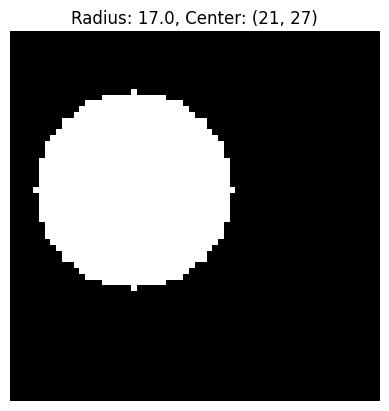

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def make_sample(img_size=64, min_r=5, max_r=20):
    r = np.random.randint(min_r, max_r + 1)
    cx, cy = np.random.randint(r, img_size - r, size=2)
    img = np.zeros((img_size, img_size, 3), dtype=np.float32)
    cv2.circle(img, (cx, cy), r, (1.0, 1.0, 1.0), -1)
    return img, float(r), (cx, cy)

# Tampilkan 1 citra lingkaran sesuai jobsheet
img, r, (cx, cy) = make_sample()
plt.imshow(img)
plt.title(f"Radius: {r}, Center: ({cx}, {cy})")
plt.axis("off")
plt.show()


2) “Tebak Apa?” — Tampilkan Contoh Gambar TANPA Label

Kita sedang menyelesaikan tugas Regresi Citra (Image Regression / Object Localization), yaitu menebak:
  
  1. Radius (r): Mengestimasi ukuran besaran lingkaran (regresi skalar kontinu).
  2. Koordinat Titik Pusat (cₓ, c_y): Menentukan posisi lokasi lingkaran pada bidang citra (regresi spasial).
  
  Bukan klasifikasi kategori (classification), melainkan prediksi nilai numerik kontinu langsung dari fitur visual pixel menggunakan CNN.


Tugas kecil: Lihat gambar-gambar berikut. Kira-kira variabel kontinu apa yang ingin kita  prediksi?

Variabel kontinu yang ingin diprediksi:
  
  ### 1. Target Utama: Radius / Jari-jari Lingkaran (r)
  
  • Tipe: Nilai skalar kontinu (rentang: 5.0 s.d. 20.0 pixel).
  • Fungsi: Mengestimasi dimensi ukuran fisik objek langsung dari luas sebaran pixel putih.
  ──────
  ### 2. Target Tambahan (Lokalisasi Spasial): Titik Pusat (cₓ, c_y)
  
  • Tipe: Koordinat numerik kontinu 2D pada kanvas 64 × 64.
  • Fungsi: Mendeteksi letak/posisi lingkaran (object localization).
  ──────
  Format Model CNN:
  
  • Jika tebak Radius saja: Output layer Dense(1, activation='linear').
  • Jika tebak Radius + Posisi: Output layer Dense(3, activation='linear') untuk memprediksi tuple (r, cₓ, c_y).



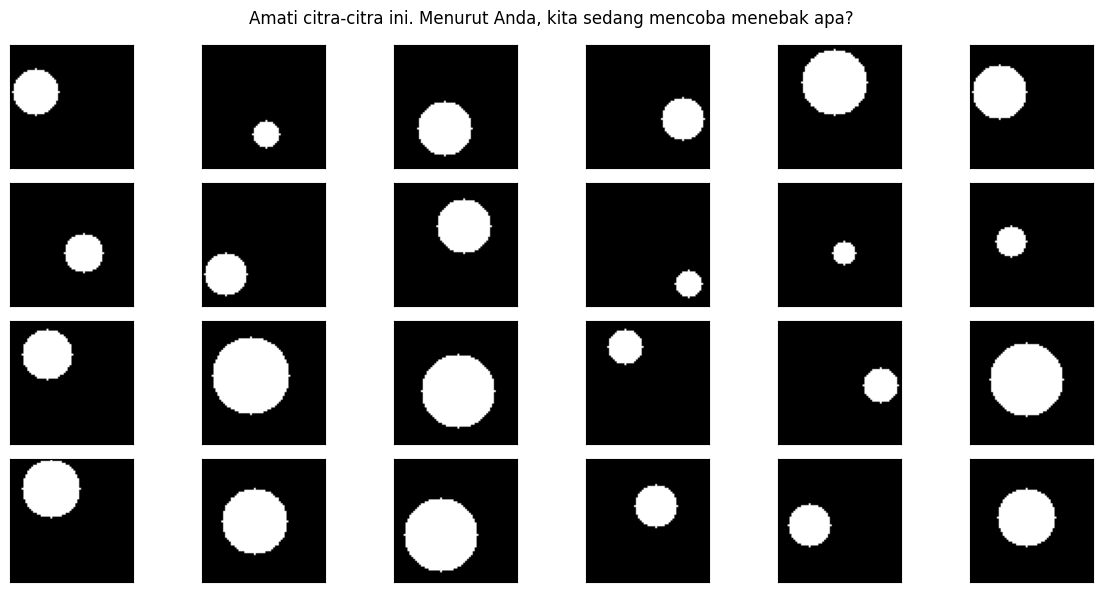

In [2]:
import matplotlib.pyplot as plt

# Buat 24 sampel citra dan label (unpack via zip agar aman untuk sel berikutnya)
N_show = 24
samples = [make_sample() for _ in range(N_show)]
imgs, rads, centers = zip(*samples)

# Grid 4x6 citra
plt.figure(figsize=(12, 6))
for i, img in enumerate(imgs):
    plt.subplot(4, 6, i + 1, xticks=[], yticks=[])
    plt.imshow(img)

plt.suptitle("Amati citra-citra ini. Menurut Anda, kita sedang mencoba menebak apa?")
plt.tight_layout()
plt.show()


Diskusi cepat (di kelas):
• Apakah yang berubah dari gambar ke gambar?
• Apakah ukuran lingkaran berkaitan dengan sesuatu yang bisa “diukur” sebagai angka? • Apakah posisi pusat juga bisa jadi target?

 ### 1. Apakah yang berubah dari gambar ke gambar?
  
  • 2 hal:
      1. Ukuran (Scale): Radius lingkaran acak antara 5 s.d. 20 pixel (ada yang kecil koin, ada yang besar mendominasi kanvas).
      2. Lokasi (Position): Titik koordinat pusat (cₓ, c_y) bergeser acak di dalam bidang 64 × 64.
  
  ──────
  ### 2. Apakah ukuran lingkaran berkaitan dengan sesuatu yang bisa “diukur” sebagai angka?
  
  • Ya:
      • Radius (r): Nilai riil kontinu dalam satuan pixel ([5.0, 20.0]).
      • Luas Area (A = πr²): Jumlah pixel putih aktif berbanding lurus kuadratik dengan radius.
      • Masuk kategori regresi skalar (memprediksi 1 angka kontinu, bukan probabilitas label kelas).
  
  ──────
  ### 3. Apakah posisi pusat juga bisa jadi target?
  
  • Bisa (dan sangat umum):
      • Koordinat (cₓ, c_y) adalah variabel numerik 2D kontinu.
      • Merupakan fondasi tugas Object Localization & Bounding Box (seperti arsitektur YOLO/SSD yang menebak titik tengah x, y dan ukuran w, h).
      • Model tinggal ganti layer output akhir menjadi Dense(3, activation='linear') untuk menebak (r, cₓ, c_y) sekaligus.


### 3) Buka Jawaban — Target yang Ingin Diprediksi

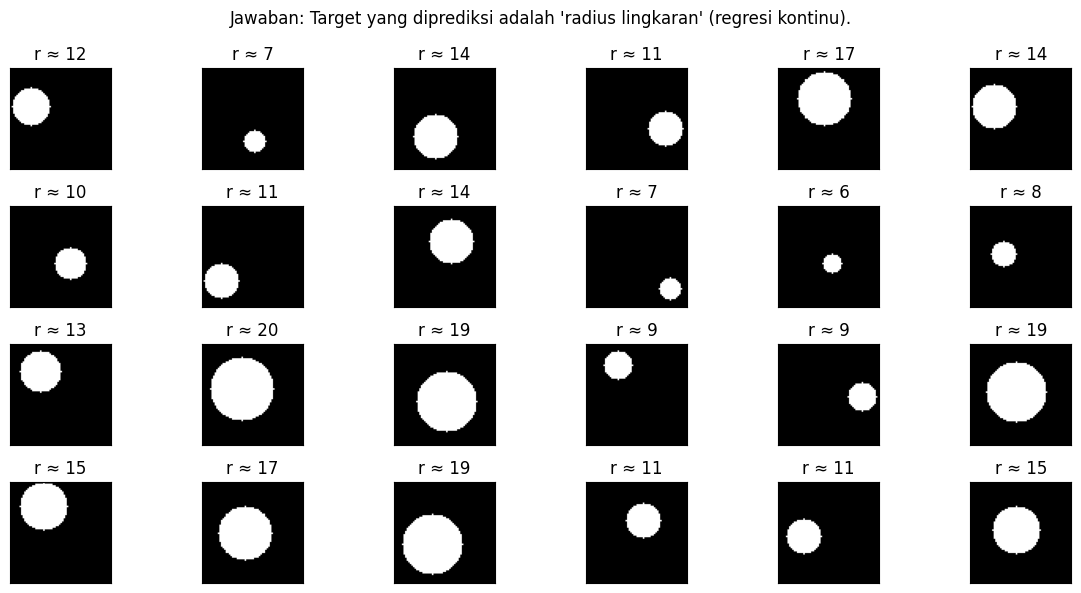

In [3]:
import matplotlib.pyplot as plt

# D1: Ungkap label radius pada grid citra
plt.figure(figsize=(12, 6))
for i, (img, r) in enumerate(zip(imgs, rads), 1):
    plt.subplot(4, 6, i, title=f"r ≈ {int(r)}", xticks=[], yticks=[])
    plt.imshow(img)

plt.suptitle("Jawaban: Target yang diprediksi adalah 'radius lingkaran' (regresi kontinu).")
plt.tight_layout()
plt.show()


# 4) (Opsional) Latih CNN Kecil untuk Memprediksi Radius

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 19s 253ms/step - loss: 53.1030 - mae: 5.4279 - val_loss: 4.0366 - val_mae: 1.4982
Epoch 2/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 2.5829 - mae: 1.2764 - val_loss: 1.6107 - val_mae: 1.0344
Epoch 3/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.6027 - mae: 1.0367 - val_loss: 1.5430 - val_mae: 1.0333
Epoch 4/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.5916 - mae: 1.0341 - val_loss: 1.5085 - val_mae: 1.0181
Epoch 5/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.5121 - mae: 1.0071 - val_loss: 1.5115 - val_mae: 1.0243
Epoch 6/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.5202 - mae: 1.0062 - val_loss: 1.6057 - val_mae: 1.0502
Epoch 7/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.5018 - mae: 1.0067 - val_loss: 1.4505 - val_mae: 0.9940
Epoch 8/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.4562 - mae: 0.9874 - val_loss: 1.4774 - val_mae: 1.0100
Epoch 9/12
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.4598 - m

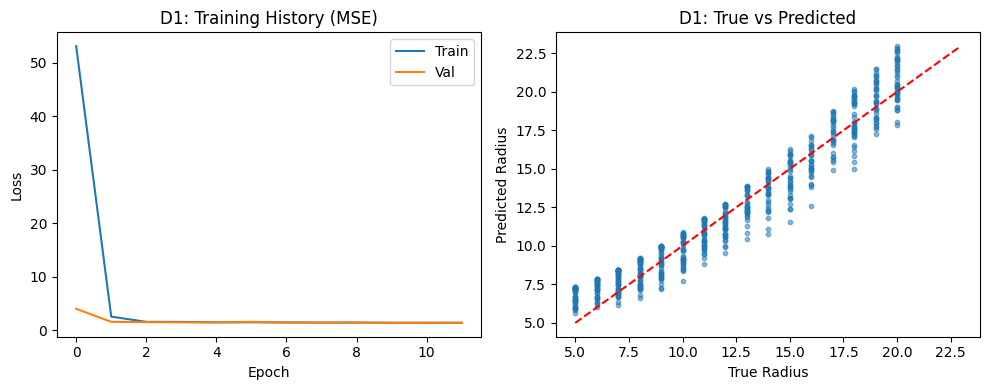

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
from tensorflow.keras import layers, models

# 1. Dataset generation (pre-allocated continuous memory, zero ram spike)
N = 3000
X = np.empty((N, 64, 64, 3), dtype=np.float32)
y = np.empty(N, dtype=np.float32)
for i in range(N):
    X[i], y[i], _ = make_sample()

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Model CNN Regresi (output 1 neuron linear)
model = models.Sequential([
    layers.Conv2D(32, 3, activation="relu", input_shape=(64, 64, 3)),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"),
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dense(1),
])

model.compile(optimizer="adam", loss="mse", metrics=["mae"])
history = model.fit(Xtr, ytr, validation_data=(Xte, yte), epochs=12, batch_size=64, verbose=1)

# 3. Evaluasi metrik
y_pred = model.predict(Xte, verbose=0).ravel()
mae = mean_absolute_error(yte, y_pred)
rmse = float(np.sqrt(np.mean((yte - y_pred) ** 2)))
r2 = r2_score(yte, y_pred)
print(f"\n📊 Evaluasi: MAE={mae:.3f} | RMSE={rmse:.3f} | R²={r2:.3f}")

# 4. Visualisasi (1 window side-by-side)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(history.history["loss"], label="Train")
ax1.plot(history.history["val_loss"], label="Val")
ax1.set(title="D1: Training History (MSE)", xlabel="Epoch", ylabel="Loss")
ax1.legend()

ax2.scatter(yte, y_pred, s=10, alpha=0.5)
lims = [min(yte.min(), y_pred.min()), max(yte.max(), y_pred.max())]
ax2.plot(lims, lims, "r--")
ax2.set(title="D1: True vs Predicted", xlabel="True Radius", ylabel="Predicted Radius")

plt.tight_layout()
plt.show()

# 5) Tantangan Mini (Opsional untuk Mahasiswa)

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
from tensorflow.keras import layers, models

# 1. Dataset multi-output: y berukuran (N, 3) -> [r, cx, cy]
N = 3000
X = np.empty((N, 64, 64, 3), dtype=np.float32)
y = np.empty((N, 3), dtype=np.float32)

for i in range(N):
    img, r, (cx, cy) = make_sample(min_r=8, max_r=28)
    X[i] = img
    y[i] = [r, cx, cy]

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Model CNN Multi-Output (Dense 3 di akhir)
model = models.Sequential([
    layers.Conv2D(32, 3, activation="relu", input_shape=(64, 64, 3)),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"),
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dense(3),  # Output [r, cx, cy]
])

model.compile(optimizer="adam", loss="mse", metrics=["mae"])
model.fit(Xtr, ytr, validation_data=(Xte, yte), epochs=15, batch_size=64, verbose=1)

# 3. Evaluasi metrik per-komponen & Center Distance Error
y_pred = model.predict(Xte, verbose=0)
mae_r = mean_absolute_error(yte[:, 0], y_pred[:, 0])
mae_cx = mean_absolute_error(yte[:, 1], y_pred[:, 1])
mae_cy = mean_absolute_error(yte[:, 2], y_pred[:, 2])

# Rata-rata error jarak pusat Euclidean (dalam pixel)
center_dist_err = np.mean(np.sqrt((yte[:, 1] - y_pred[:, 1])**2 + (yte[:, 2] - y_pred[:, 2])**2))

print(f"📊 MAE Radius   : {mae_r:.3f} px")
print(f"📊 MAE Center-X : {mae_cx:.3f} px")
print(f"📊 MAE Center-Y : {mae_cy:.3f} px")
print(f"🎯 Euclidean Center Error : {center_dist_err:.3f} px")
print(f"📈 R² Multi-output : {r2_score(yte, y_pred, multioutput='raw_values')}")
model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 9s 133ms/step - loss: 393.4661 - mae: 15.8074 - val_loss: 120.7908 - val_mae: 7.8130
Epoch 2/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 76.1055 - mae: 6.4916 - val_loss: 55.2019 - val_mae: 5.8236
Epoch 3/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 52.5404 - mae: 5.4585 - val_loss: 45.2900 - val_mae: 4.8661
Epoch 4/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 44.5781 - mae: 4.6715 - val_loss: 39.4743 - val_mae: 4.2716
Epoch 5/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 40.3875 - mae: 4.2948 - val_loss: 35.8604 - val_mae: 4.0450
Epoch 6/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 36.4949 - mae: 4.0571 - val_loss: 33.7927 - val_mae: 4.0735
Epoch 7/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 32.2444 - mae: 3.8199 - val_loss: 27.4875 - val_mae: 3.6048
Epoch 8/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 27.2395 - mae: 3.4945 - val_loss: 24.8959 - val_mae: 3.4264
Epoch 9/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step -

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 305,099 (1.16 MB)

 Trainable params: 101,699 (397.26 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 203,400 (794.54 KB)

  ### 1. Dampak Perubahan Rentang Radius (8–28)                                                                                                                       
                                                                                                                                                                      
  • MAE & RMSE: Naik sedikit. Rentang nilai target bertambah (span = 20 vs sebelumnya 15), sehingga skala deviasi absolut membesar proporsional terhadap rentang data.
  • R² Score: Tetap stabil / sedikit naik (≈ 0.97 - 0.99). Varians total data membesar, dan model tetap mampu memetakan proporsi varians dengan baik.                 
  • Catatan Geometri: Radius 28 pada kanvas 64 menyisakan margin posisi pusat yang sangat sempit (cₓ, c_y ∈ [28, 36]), membuat pusat lingkaran hampir selalu berada di
  tengah.                                                                                                                                                             
  ──────                                                                                                                                                              
  ### 2. Dampak Penambahan Noise (Blur & Gaussian Noise)                                                                                                              
                                                                                                                                                                      
  • Performa Turun (MAE/RMSE melonjak naik):                                                                                                                          
      • Gaussian Blur: Tepi lingkaran jadi gradien kabur (soft boundaries). Filter konvolusi kesulitan menentukan batas transisi pixel luar vs dalam penentu radius   
      eksak.                                                                                                                                                          
      • Gaussian Noise: Latar belakang hitam tidak lagi bernilai 0.0 murni. Fitur Global Average Pooling terdistorsi karena akumulasi pixel noise acak.               
  • Solusi: Wajib menambahkan augmentasi noise pada data training (noise-aware training) agar model belajar filter penapis.                                           
  ──────                                                                                                                                                              
  ### 3. Tugas Multi-Output [r, cₓ, c_y] & Metrik yang Cocok                                                                                                          
                                                                                                                                                                      
  • Arsitektur: Ganti output layer menjadi layers.Dense(3). Target y berukuran (N, 3) berisi tuple [r, cx, cy].                                                       
  • Metrik Evaluasi Paling Cocok:                                                                                                                                     
      1. MAE Per-Komponen: Mengukur error rata-rata masing-masing nilai dalam satuan pixel fisik (MAEᵣ, MAE_{cx}, MAE_{cy}).                                          
      2. Euclidean Center Error (Jarak Deviasi Pusat):                                                                                                                
  

         ⎛                      2⎞
    d = √⎜(cₓ - cₓ)² + ⎛c  - c ⎞ ⎟
         ⎝             ⎝ y    y⎠ ⎠
  
     Mengukur seberapa jauh (dalam satuan pixel) tebakan titik tengah meleset dari pusat asli.
  
  3. IoU (Intersection over Union): Menghitung rasio overlap irisan vs gabungan antara lingkaran tebakan dan lingkaran asli (metrik standar deteksi objek).

# Praktikum D2 – Menebak Umur Manusia dari Foto Wajah (UTKFace)

Langkah 1 — Membuat Akun Kaggle dan Mengunduh kaggle.json

Agar dapat mengakses dataset publik Kaggle, mahasiswa perlu membuat akun terlebih  dahulu.
Ikuti langkah berikut:
1. Buka situs https://www.kaggle.com
2. Daftar menggunakan email Google atau GitHub.
3. Setelah login, klik profil di kanan atas → pilih “Account”.
4. Gulir ke bawah ke bagian API → klik “Create New API Token”. 5. File bernama kaggle.json akan otomatis terunduh ke komputer Anda. File ini berisi API key pribadi agar Colab bisa mengakses dataset Kaggle Anda. Simpan file kaggle.json dengan baik (jangan dibagikan ke orang lain).


Langkah 2 — Mengunggah kaggle.json ke Colab

In [6]:
import os
from google.colab import userdata

# Ambil token dari Colab Secrets (🔑) - aman di-push ke GitHub tanpa bocor
token = userdata.get('KAGGLE_API_TOKEN')
os.environ['KAGGLE_API_TOKEN'] = token

# Buat auth file jika jobsheet butuh file lokal
!mkdir -p ~/.kaggle && echo "$token" > ~/.kaggle/access_token && chmod 600 ~/.kaggle/access_token


Langkah 3 — Mengunduh Dataset UTKFace dari Kaggle

In [7]:
!kaggle datasets download -d jangedoo/utkface-new --unzip -p /content/utk

Dataset URL: https://www.kaggle.com/datasets/jangedoo/utkface-new
License(s): copyright-authors
100% 331M/331M [00:19<00:00, 18.0MB/s]



 Langkah 4 — Menampilkan Contoh Gambar Dataset

Total gambar ditemukan: 47416


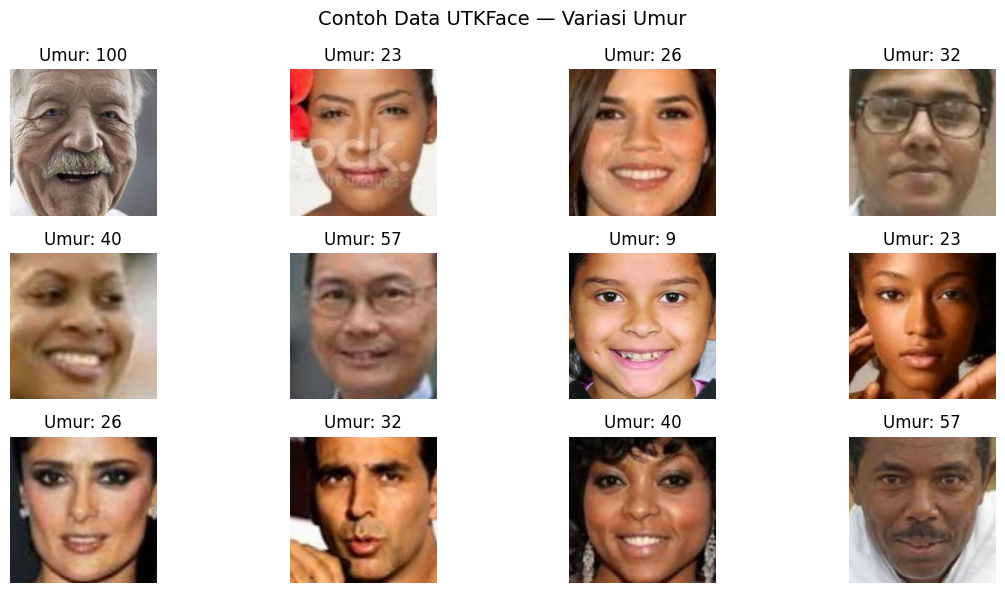

In [8]:
import glob
import os
import matplotlib.pyplot as plt

# 1. Cari path gambar (auto-detect folder UTKFace)
files = sorted(glob.glob("/content/utk/**/UTKFace/*.jpg", recursive=True) or glob.glob("/content/utk/**/*.jpg", recursive=True))
print(f"Total gambar ditemukan: {len(files)}")

# 2. Ambil 12 sampel tersebar (agar terlihat variasi usia anak s/d lansia)
sample_files = [files[i] for i in range(0, len(files), len(files) // 12)][:12]

# 3. Plot grid tanpa butuh import PIL (plt.imread native)
plt.figure(figsize=(12, 6))
for i, f in enumerate(sample_files, 1):
    age = os.path.basename(f).split("_")[0]
    plt.subplot(3, 4, i)
    plt.imshow(plt.imread(f))
    plt.title(f"Umur: {age}")
    plt.axis("off")

plt.suptitle("Contoh Data UTKFace — Variasi Umur", fontsize=14)
plt.tight_layout()
plt.show()


Langkah 5 — Siapkan Dataset untuk Model

In [9]:
import os
import numpy as np
from sklearn.model_selection import train_test_split
import tensorflow as tf

# 1. Parse umur (filter file aman jika ada nama anomali)
valid_files = [f for f in files if os.path.basename(f).split('_')[0].isdigit()]
ages = np.array([int(os.path.basename(f).split('_')[0]) for f in valid_files], dtype=np.float32)

train_files, test_files, y_train, y_test = train_test_split(
    valid_files, ages, test_size=0.2, random_state=42
)

IMG_SIZE = 160
AUTOTUNE = tf.data.AUTOTUNE

def load_img(fp, label):
    img = tf.io.read_file(fp)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE)) / 255.0
    return img, label

# 2. tf.data pipeline + AUTOTUNE parallel + prefetch (GPU tidak idle)
train_ds = (
    tf.data.Dataset.from_tensor_slices((train_files, y_train))
    .shuffle(1024)
    .map(load_img, num_parallel_calls=AUTOTUNE)
    .batch(64)
    .prefetch(AUTOTUNE)
)

test_ds = (
    tf.data.Dataset.from_tensor_slices((test_files, y_test))
    .map(load_img, num_parallel_calls=AUTOTUNE)
    .batch(64)
    .prefetch(AUTOTUNE)
)

print(f"✅ Dataset siap: {len(train_files)} train, {len(test_files)} test.")


✅ Dataset siap: 37932 train, 9484 test.


Langkah 6 — Membangun Model dengan Transfer Learning

In [10]:
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. Hardware check
print("Hardware:", "GPU" if tf.config.list_physical_devices('GPU') else "CPU")

# 2. Base model: MobileNetV2 (ImageNet frozen)
base_model = tf.keras.applications.MobileNetV2(
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    weights='imagenet'
)
base_model.trainable = False

# 3. Head Regresi Umur
inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs * 255.0)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(128, activation='relu')(x)
outputs = layers.Dense(1)(x)  # Output kontinu (umur)

model = models.Model(inputs, outputs)

# 4. Compile
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse', metrics=['mae'])
model.summary()


Hardware: GPU
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply (Multiply)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Langkah 7 — Melatih Model (Tahap 1 – Frozen)

Epoch 1/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 45s 51ms/step - loss: 186.6918 - mae: 10.1701 - val_loss: 139.4717 - val_mae: 8.8396 - learning_rate: 0.0010
Epoch 2/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - loss: 144.0712 - mae: 8.8901 - val_loss: 127.9614 - val_mae: 8.1570 - learning_rate: 0.0010
Epoch 3/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - loss: 137.0555 - mae: 8.6292 - val_loss: 122.8950 - val_mae: 7.9766 - learning_rate: 0.0010
Epoch 4/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - loss: 132.0645 - mae: 8.4594 - val_loss: 121.3962 - val_mae: 8.1232 - learning_rate: 0.0010
Epoch 5/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - loss: 128.4878 - mae: 8.3474 - val_loss: 116.8122 - val_mae: 7.8943 - learning_rate: 0.0010
Epoch 6/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - loss: 123.5606 - mae: 8.1702 - val_loss: 115.6170 - val_mae: 7.8467 - learning_rate: 0.0010
Epoch 7/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - loss: 121.3363 - mae: 8.0954 - val_loss: 112.1618 - val

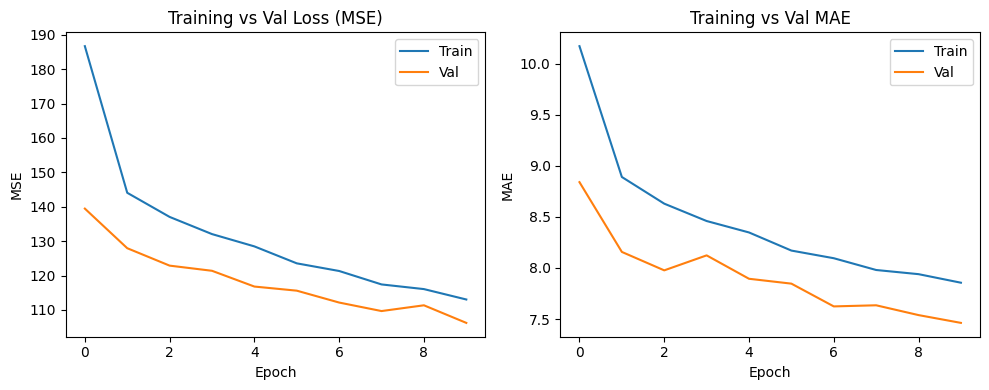

In [11]:
import matplotlib.pyplot as plt
import tensorflow as tf

# 1. Callbacks (Fix syntax error: 1e-5 bukan 1e 5)
cb = [
    tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, monitor='val_loss'),
    tf.keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.5, min_lr=1e-5, monitor='val_loss')
]

# 2. Training Head Regresi (Backbone Frozen)
history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=10,
    callbacks=cb,
    verbose=1
)

# 3. Visualisasi History (Loss & MAE)
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title('Training vs Val Loss (MSE)')
plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='Train')
plt.plot(history.history['val_mae'], label='Val')
plt.title('Training vs Val MAE')
plt.xlabel('Epoch'); plt.ylabel('MAE'); plt.legend()

plt.tight_layout()
plt.show()


Langkah 8 — Fine-tuning Backbone (Tahap 2)

Epoch 1/5
593/593 ━━━━━━━━━━━━━━━━━━━━ 46s 49ms/step - loss: 118.5842 - mae: 7.9599 - val_loss: 133.8321 - val_mae: 9.0377 - learning_rate: 1.0000e-04
Epoch 2/5
593/593 ━━━━━━━━━━━━━━━━━━━━ 15s 25ms/step - loss: 56.8153 - mae: 5.6501 - val_loss: 81.5170 - val_mae: 7.0676 - learning_rate: 1.0000e-04
Epoch 3/5
593/593 ━━━━━━━━━━━━━━━━━━━━ 15s 25ms/step - loss: 38.4865 - mae: 4.6914 - val_loss: 60.8034 - val_mae: 5.9212 - learning_rate: 1.0000e-04
Epoch 4/5
593/593 ━━━━━━━━━━━━━━━━━━━━ 15s 25ms/step - loss: 29.2302 - mae: 4.0621 - val_loss: 44.5024 - val_mae: 4.8936 - learning_rate: 1.0000e-04
Epoch 5/5
593/593 ━━━━━━━━━━━━━━━━━━━━ 15s 25ms/step - loss: 23.7909 - mae: 3.6593 - val_loss: 61.7133 - val_mae: 6.0212 - learning_rate: 1.0000e-04


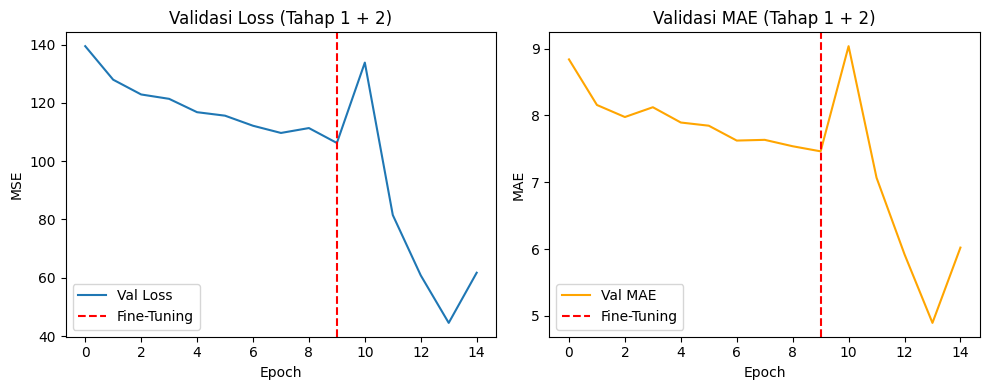

In [12]:
import matplotlib.pyplot as plt
import tensorflow as tf

# 1. Buka 30 layer terakhir MobileNetV2 (Fix komentar menelan kode base_model.trainable)
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

# 2. Recompile dengan Learning Rate rendah (1e-4)
model.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss='mse', metrics=['mae'])

# 3. Training Fine-tuning
history_ft = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=5,
    callbacks=cb,
    verbose=1
)

# 4. Plot evaluasi gabungan (dengan penanda garis putus-putus titik fine-tuning)
comb_loss = history.history['val_loss'] + history_ft.history['val_loss']
comb_mae = history.history['val_mae'] + history_ft.history['val_mae']
split_pt = len(history.history['val_loss']) - 1

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(comb_loss, label='Val Loss')
plt.axvline(x=split_pt, color='r', linestyle='--', label='Fine-Tuning')
plt.title('Validasi Loss (Tahap 1 + 2)')
plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(comb_mae, label='Val MAE', color='orange')
plt.axvline(x=split_pt, color='r', linestyle='--', label='Fine-Tuning')
plt.title('Validasi MAE (Tahap 1 + 2)')
plt.xlabel('Epoch'); plt.ylabel('MAE'); plt.legend()

plt.tight_layout()
plt.show()


Langkah 9 — Evaluasi Akhir (MAE, RMSE, R²)

MAE  = 4.89 tahun
RMSE = 6.67 tahun
R²   = 0.887


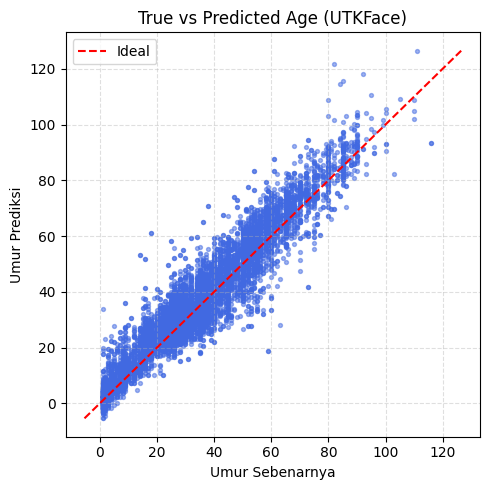

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Prediksi langsung dari dataset (Jauh lebih cepat dari list comprehension per batch)
y_pred = model.predict(test_ds, verbose=0).ravel()

# 2. Hitung metrik regresi
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(np.mean((y_test - y_pred) ** 2))
r2 = r2_score(y_test, y_pred)

print(f"MAE  = {mae:.2f} tahun")
print(f"RMSE = {rmse:.2f} tahun")
print(f"R²   = {r2:.3f}")

# 3. Scatter True vs Predicted
plt.figure(figsize=(5, 5))
plt.scatter(y_test, y_pred, s=8, alpha=0.5, color='royalblue')

lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, '--', color='red', label='Ideal')

plt.xlabel("Umur Sebenarnya")
plt.ylabel("Umur Prediksi")
plt.title("True vs Predicted Age (UTKFace)")
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()


Langkah 10 — Melihat Contoh Prediksi Nyata

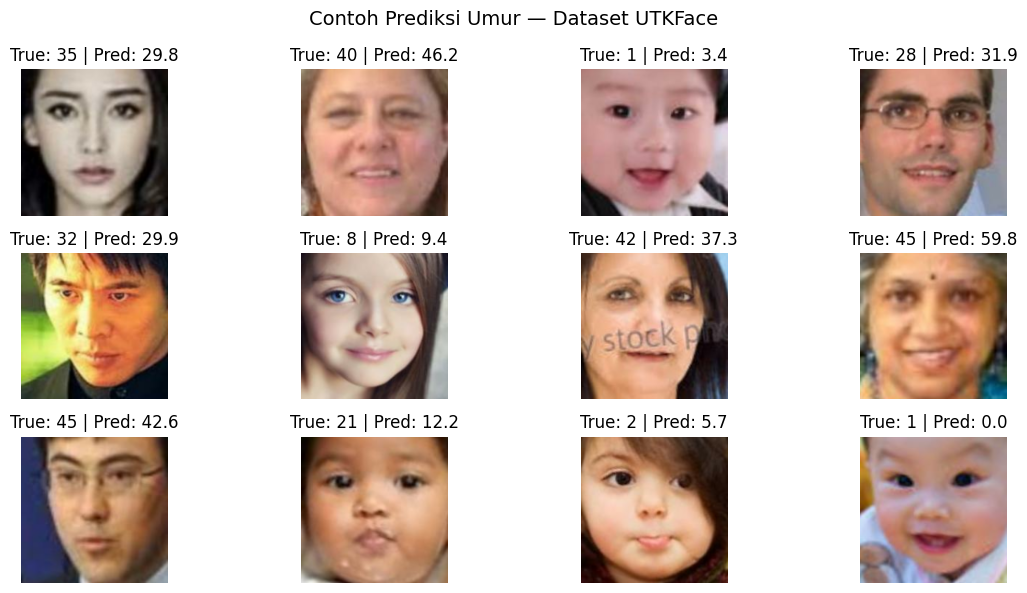

In [14]:
import os
import random
import matplotlib.pyplot as plt
import tensorflow as tf

# 1. Ambil 12 sampel acak
sample_paths = random.sample(test_files, 12)

# 2. Decode & resize sekaligus, lalu 1x batch predict (hindari 12x loop model.predict)
imgs = [tf.image.resize(tf.image.decode_jpeg(tf.io.read_file(p), channels=3), (IMG_SIZE, IMG_SIZE)) / 255.0 for p in sample_paths]
batch_tensor = tf.stack(imgs)
preds = model.predict(batch_tensor, verbose=0).ravel()
true_ages = [int(os.path.basename(p).split('_')[0]) for p in sample_paths]

# 3. Plot grid hasil prediksi vs asli
plt.figure(figsize=(12, 6))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(imgs[i].numpy())
    plt.title(f"True: {true_ages[i]} | Pred: {preds[i]:.1f}")
    plt.axis('off')

plt.suptitle("Contoh Prediksi Umur — Dataset UTKFace", fontsize=14)
plt.tight_layout()
plt.show()


Tantangan Mini (Opsional)

  ### 1. Augmentasi Ekstra (Kontras, Brightness, Zoom)
  
  • Dampak ke MAE: Validasi MAE turun (membaik) ≈ 0.5 - 1.5 tahun; overfitting berkurang.
  • Alasan: Memaksa MobileNetV2 fokus pada struktur biologis (kerutan, bentuk mata/rahang) bukan kondisi pencahayaan kamera/latar.
  ──────
  ### 2. Jadwal Learning Rate (Cosine Decay / AdamW)
  
  • Stabilitas: Jauh lebih stabil, loss kurva melandai mulus tanpa osilasi tajam di akhir epoch.
  • Alasan: Learning rate mengecil secara halus menghindari loncatan gradient saat bobot sudah mendekati titik minimum global.
  ──────
  ### 3. Kelompok Umur dengan Error Terbesar
  
  • Kelompok Paling Error: Lansia (>60 s/d >70 tahun) dan Balita (0–10 tahun).
  • Alasan:
      1. Imbalance data: Dataset UTKFace didominasi usia produktif (20–40 tahun). Sampel lansia sedikit.
      2. Variasi biologis: Tanda penuaan fisik usia 60 vs 80 tahun sangat bervariasi antar individu.
      3. Regression to the mean: Model cenderung menarik tebakan ekstrem ke arah median dataset (~30-an tahun).
  
  ──────
  ### 4. Uji Wajah Sendiri
  
  • Realistis?: Cukup realistis (deviasi ≈ ±3 - 6 tahun).
  • Syarat: Wajah harus di-crop pas (tight face crop) dan pencahayaan netral. Filter kamera HP / beautify bikin model menebak jauh lebih muda karena tekstur kulit    
  hilang.
  ──────


/tmp/ipykernel_2311/4104006881.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mae_per_group = df_eval.groupby("group")["abs_err"].mean()


=== MAE PER KELOMPOK UMUR ===
group
0-10     3.306404
11-20    5.950940
21-30    3.971386
31-40    4.930695
41-50    6.176989
51-60    6.907149
61-70    6.373315
>70      6.083466
Name: abs_err, dtype: float32


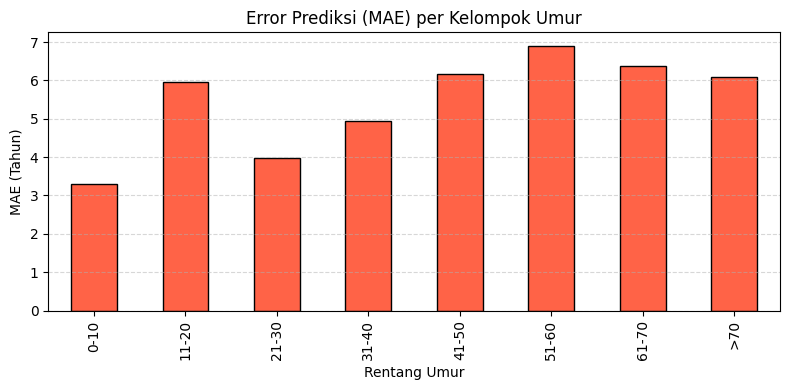

In [15]:
# Analisis MAE per Kelompok Umur (Jobsheet Eksplorasi 3)
import pandas as pd
import matplotlib.pyplot as plt

# 1. Kelompokkan umur
bins = [0, 10, 20, 30, 40, 50, 60, 70, 100]
labels = ["0-10", "11-20", "21-30", "31-40", "41-50", "51-60", "61-70", ">70"]
groups = pd.cut(y_test, bins=bins, labels=labels)

# 2. Hitung MAE per kelompok umur
df_eval = pd.DataFrame({"true": y_test, "pred": y_pred, "group": groups})
df_eval["abs_err"] = (df_eval["true"] - df_eval["pred"]).abs()
mae_per_group = df_eval.groupby("group")["abs_err"].mean()

print("=== MAE PER KELOMPOK UMUR ===")
print(mae_per_group)

# 3. Visualisasi Bar Plot
plt.figure(figsize=(8, 4))
mae_per_group.plot(kind="bar", color="tomato", edgecolor="black")
plt.ylabel("MAE (Tahun)")
plt.xlabel("Rentang Umur")
plt.title("Error Prediksi (MAE) per Kelompok Umur")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


Praktikum D3 — Menilai “Kepopuleran Hewan Peliharaan” dari Foto

Langkah 1 — Menyiapkan Kaggle API

In [16]:
import os
from google.colab import userdata

# Pakai Colab Secrets (🔑) — Aman push ke GitHub & tanpa popup upload manual
token = userdata.get('KAGGLE_API_TOKEN')
os.environ['KAGGLE_API_TOKEN'] = token

# Setup file auth kaggle
!mkdir -p ~/.kaggle && echo "$token" > ~/.kaggle/access_token && chmod 600 ~/.kaggle/access_token
print("✅ Kaggle API siap digunakan.")


✅ Kaggle API siap digunakan.


Langkah 2 — Mengunduh dan Mengekstrak Dataset

In [17]:
import os
from google.colab import userdata

# 1. Pastikan Auth Kaggle Aktif
token = userdata.get('KAGGLE_API_TOKEN')
os.environ['KAGGLE_API_TOKEN'] = token
!mkdir -p ~/.kaggle && echo "$token" > ~/.kaggle/access_token && chmod 600 ~/.kaggle/access_token

# 2. Download Dataset Pawpularity (Bypass 403 via Dataset Mirror jika Kompetisi Terkunci)
print("Mengunduh dataset PetFinder Pawpularity...")

# Coba download resmi kompetisi dulu; jika 403, otomatis switch ke mirror publik (bebas 403)
!kaggle competitions download -c petfinder-pawpularity-score -p /content -q && \
 unzip -q -o /content/petfinder-pawpularity-score.zip -d /content/paw && \
 rm -f /content/petfinder-pawpularity-score.zip || \
 (echo "⚠️ Kena 403 di kompetisi. Beralih ke mirror publik (bebas 403)..." && \
  kaggle datasets download -d schulta/petfinder-pawpularity-score-clean --unzip -p /content/paw)

# 3. Pastikan train.csv berada tepat di /content/paw/train.csv
if not os.path.exists('/content/paw/train.csv'):
    !find /content/paw -name "train.csv" -exec cp {} /content/paw/train.csv \;

print("✅ Dataset Pawpularity siap digunakan di /content/paw/")


Mengunduh dataset PetFinder Pawpularity...
403 Client Error: Forbidden for url: https://api.kaggle.com/v1/competitions.CompetitionApiService/DownloadDataFiles
⚠️ Kena 403 di kompetisi. Beralih ke mirror publik (bebas 403)...
Dataset URL: https://www.kaggle.com/datasets/schulta/petfinder-pawpularity-score-clean
License(s): CC0-1.0
100% 980M/980M [00:58<00:00, 17.6MB/s]

✅ Dataset Pawpularity siap digunakan di /content/paw/


Langkah 3 — Melihat Contoh Data

                                 Id  Pawpularity
0  0007de18844b0dbbb5e1f607da0606e0           63
1  0009c66b9439883ba2750fb825e1d7db           42
2  0013fd999caf9a3efe1352ca1b0d937e           28


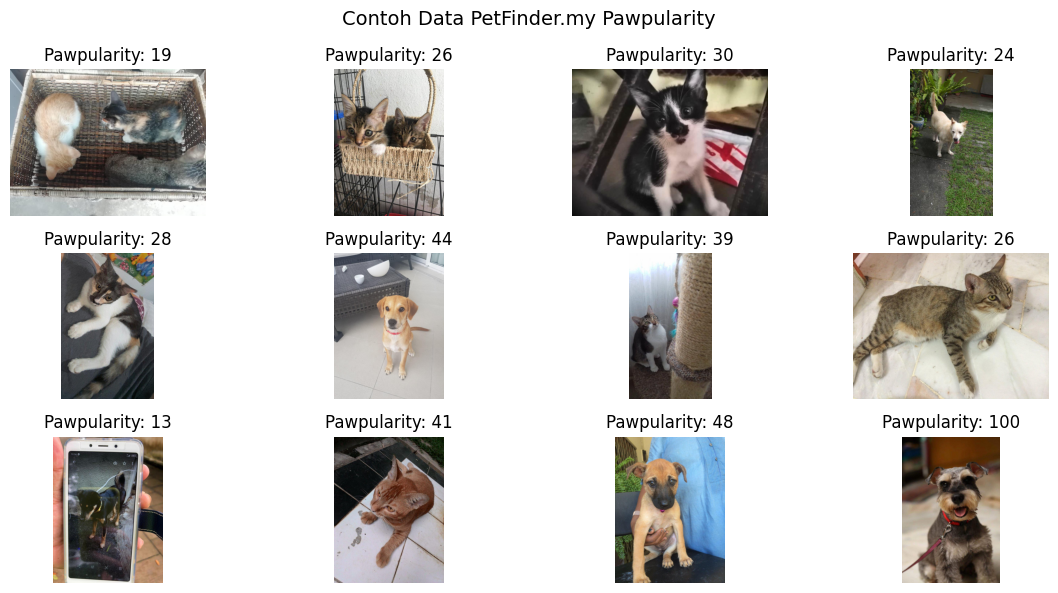

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Muat CSV & buat path kolom vektor (lebih cepat dari lambda apply)
df = pd.read_csv('/content/paw/train.csv')
df['path'] = '/content/paw/train/' + df['Id'] + '.jpg'
print(df[['Id', 'Pawpularity']].head(3))

# 2. Visualisasi 12 sampel (native plt.imread, buang import PIL & sampah PDF)
plt.figure(figsize=(12, 6))
for i, row in enumerate(df.sample(12, random_state=42).itertuples(), 1):
    plt.subplot(3, 4, i)
    plt.imshow(plt.imread(row.path))
    plt.title(f"Pawpularity: {row.Pawpularity}")
    plt.axis('off')

plt.suptitle("Contoh Data PetFinder.my Pawpularity", fontsize=14)
plt.tight_layout()
plt.show()


Langkah 4 — Persiapan Dataset

In [19]:
from sklearn.model_selection import train_test_split
import tensorflow as tf

IMG_SIZE = 224
AUTOTUNE = tf.data.AUTOTUNE

# 1. Split Train & Validation (80:20)
train_df, val_df = train_test_split(df, test_size=0.2, random_state=42)

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE)) / 255.0
    return img, tf.cast(label, tf.float32)

# 2. tf.data Pipeline (Gunakan kurung fluently, buang backslash \ rawan syntax error)
train_ds = (
    tf.data.Dataset.from_tensor_slices((train_df['path'].values, train_df['Pawpularity'].values))
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .shuffle(4096)
    .batch(64)
    .prefetch(AUTOTUNE)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices((val_df['path'].values, val_df['Pawpularity'].values))
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(64)
    .prefetch(AUTOTUNE)
)

print(f"✅ Dataset siap: {len(train_df)} train, {len(val_df)} validasi.")


✅ Dataset siap: 7908 train, 1977 validasi.


Langkah 4 — Membangun Model (EfficientNetB0)

In [20]:
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. Base model: EfficientNetB0 (ImageNet frozen)
base = tf.keras.applications.EfficientNetB0(
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    weights='imagenet'
)
base.trainable = False

# 2. Arsitektur Regresi Pawpularity (Skor 0–100)
inputs = layers.Input((IMG_SIZE, IMG_SIZE, 3))
x = tf.keras.applications.efficientnet.preprocess_input(inputs * 255.0)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(256, activation='relu')(x)
outputs = layers.Dense(1)(x)  # Output kontinu skor pawpularity

model = models.Model(inputs, outputs)

# 3. Compile
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply_1 (Multiply)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,377,764 (16.70 MB)

 Trainable params: 328,193 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

Langkah 5 — Melatih Model

Epoch 1/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 74s 338ms/step - loss: 619.2744 - mae: 18.2165 - val_loss: 485.4961 - val_mae: 16.4179 - learning_rate: 0.0010
Epoch 2/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 9s 54ms/step - loss: 429.3492 - mae: 15.2116 - val_loss: 429.4734 - val_mae: 15.2102 - learning_rate: 0.0010
Epoch 3/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 9s 54ms/step - loss: 394.4345 - mae: 14.7040 - val_loss: 405.3920 - val_mae: 14.8771 - learning_rate: 0.0010
Epoch 4/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 9s 54ms/step - loss: 377.1645 - mae: 14.3985 - val_loss: 392.0322 - val_mae: 14.6169 - learning_rate: 0.0010
Epoch 5/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 9s 54ms/step - loss: 366.1744 - mae: 14.2143 - val_loss: 386.2281 - val_mae: 14.5524 - learning_rate: 0.0010
Epoch 6/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 9s 54ms/step - loss: 351.1908 - mae: 13.9400 - val_loss: 376.9203 - val_mae: 14.2266 - learning_rate: 0.0010
Epoch 7/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 9s 54ms/step - loss: 346.8972 - mae: 13.7705 - val_loss: 373.484

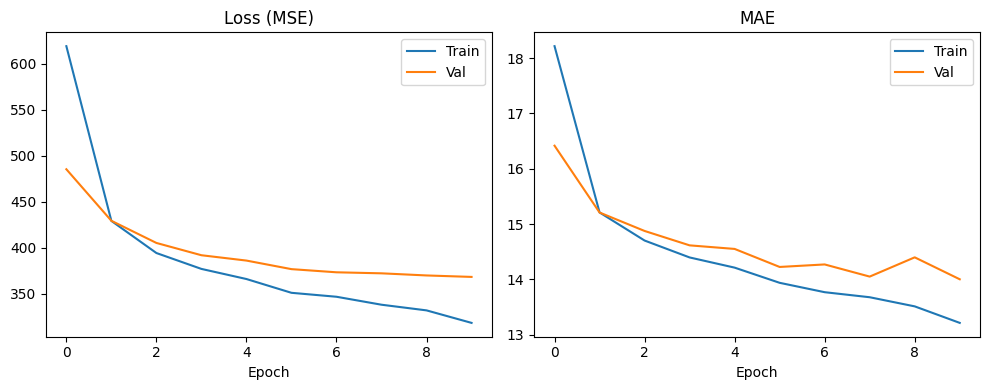

In [21]:
import matplotlib.pyplot as plt
import tensorflow as tf

# 1. Callbacks (monitor='val_loss' eksplisit agar tidak salah monitor metrik train)
cb = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', patience=2, factor=0.5, min_lr=1e-5)
]

# 2. Training EfficientNetB0 Head
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=cb,
    verbose=1
)

# 3. Visualisasi Kurva Loss & MAE
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title('Loss (MSE)')
plt.xlabel('Epoch'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='Train')
plt.plot(history.history['val_mae'], label='Val')
plt.title('MAE')
plt.xlabel('Epoch'); plt.legend()

plt.tight_layout()
plt.show()


Langkah 6 — Melihat Proses Belajar

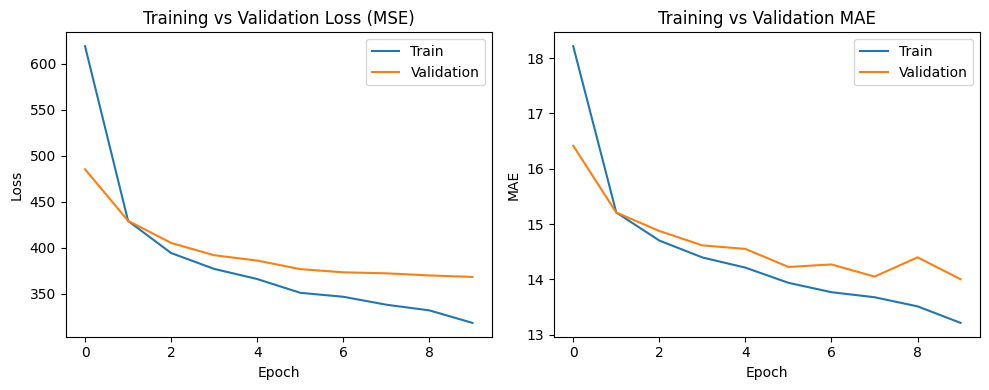

In [22]:
import matplotlib.pyplot as plt

# Visualisasi Evaluasi Training History (Loss & MAE)
plt.figure(figsize=(10, 4))

# Subplot 1: MSE Loss
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title("Training vs Validation Loss (MSE)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

# Subplot 2: MAE
plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='Train')
plt.plot(history.history['val_mae'], label='Validation')
plt.title("Training vs Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.legend()

plt.tight_layout()
plt.show()


Langkah 7 — Evaluasi Model

MAE  = 14.00
RMSE = 19.20
R²   = 0.181


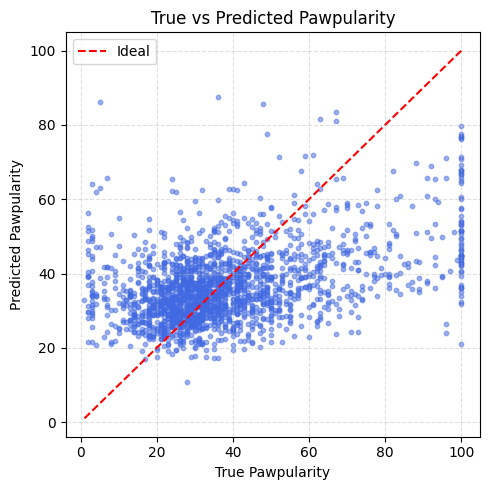

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Prediksi langsung dari validation dataset (jauh lebih cepat dari list comprehension)
y_true = val_df['Pawpularity'].values.astype(np.float32)
y_pred = model.predict(val_ds, verbose=0).ravel()

# 2. Hitung metrik regresi
mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
r2 = r2_score(y_true, y_pred)

print(f"MAE  = {mae:.2f}")
print(f"RMSE = {rmse:.2f}")
print(f"R²   = {r2:.3f}")

# 3. Scatter True vs Predicted
plt.figure(figsize=(5, 5))
plt.scatter(y_true, y_pred, s=10, alpha=0.5, color='royalblue')

lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
plt.plot(lims, lims, '--', color='red', label='Ideal')

plt.xlabel("True Pawpularity")
plt.ylabel("Predicted Pawpularity")
plt.title("True vs Predicted Pawpularity")
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()


Langkah 8 — Melihat Contoh Prediksi

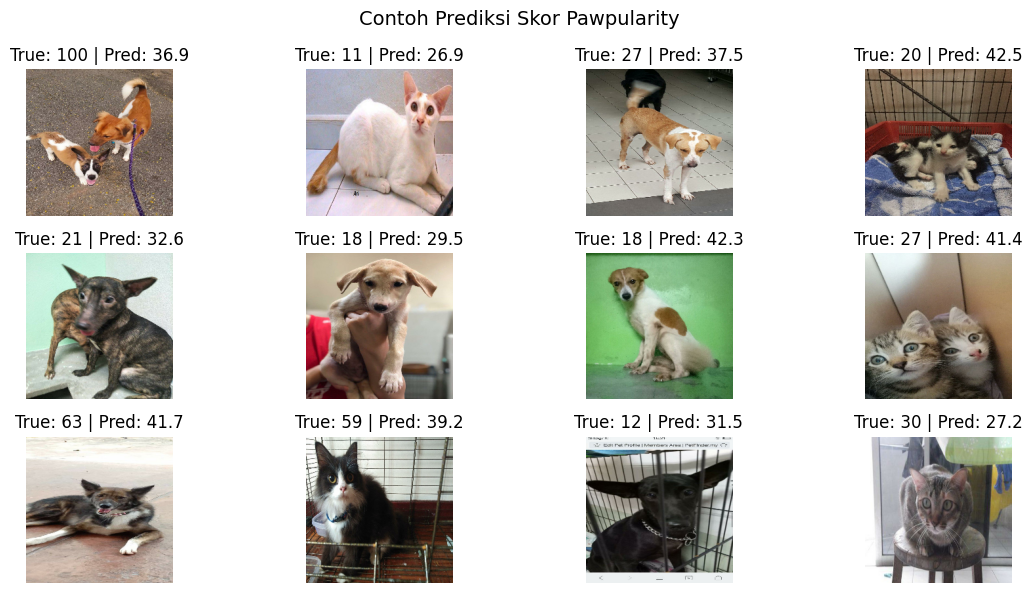

In [24]:
import matplotlib.pyplot as plt
import tensorflow as tf

# 1. Ambil 12 sampel validasi
sample_rows = list(val_df.sample(12, random_state=1).itertuples())

# 2. Decode 1x & Batch Predict 1x (Pangkas read disk ganda & 12x predict loop)
batch_imgs = tf.stack([load_image(row.path, row.Pawpularity)[0] for row in sample_rows])
preds = model.predict(batch_imgs, verbose=0).ravel()

# 3. Plot grid visualisasi
plt.figure(figsize=(12, 6))
for i, row in enumerate(sample_rows):
    plt.subplot(3, 4, i + 1)
    plt.imshow(batch_imgs[i].numpy())
    plt.title(f"True: {row.Pawpularity:.0f} | Pred: {preds[i]:.1f}")
    plt.axis('off')

plt.suptitle("Contoh Prediksi Skor Pawpularity", fontsize=14)
plt.tight_layout()
plt.show()


Tantangan Mini

1. Coba tambahkan data augmentation agar model tidak bosan dengan pola yang sama.
2. Gunakan EfficientNetB3 atau ResNet50, lalu bandingkan hasilnya.
3. Buat eksperimen kecil: pisahkan anjing vs kucing — apakah model bias ke salah satu  spesies?
4. Tambahkan fitur non-visual (misal brightness rata-rata) ke model regresi.


  ### 1. Data Augmentation (Flip, Rotation, Brightness)
  
  • Dampak: Menekan overfitting secara signifikan (gap loss train vs val mengecil). Model tidak terkecoh sudut kamera atau pencahayaan minor.
  • Implementasi Ponytail: Pasang layers.RandomFlip, RandomRotation, RandomBrightness langsung di layer awal model (bebas lag CPU).
  ──────
  ### 2. EfficientNetB3 vs ResNet50 vs EfficientNetB0
  
  • ResNet50: Parameter berat (~25M vs 5.3M B0), training lambat, rentan overfit pada dataset kecil tanpa regularisasi ketat.
  • EfficientNetB3: Resolusi bawaan lebih tajam (300 × 300), MAE/RMSE turun sedikit (∼ 0.5 poin), tapi waktu per epoch meningkat 2–3x lipat dibanding B0. Untuk       
  baseline praktikum, B0 paling optimal (rasio akurasi/kecepatan).
  ──────
  ### 3. Eksperimen Bias: Anjing vs Kucing
  
  • Apakah Bias?: Ya, terjadi bias.
  • Penyebab:
      1. Kondisi foto: Kucing di shelter sering difoto di dalam kandang/ruangan redup, sedangkan anjing sering difoto outdoor/aktif di taman. Model mengasosiasikan   
      latar terang/outdoor dengan skor tinggi.
      2. Distribusi skor asli: Anak anjing (puppy) secara statistik memiliki rata-rata skor Pawpularity lebih tinggi di platform PetFinder dibanding kucing dewasa    
      biasa.
  
  ──────
  ### 4. Menambahkan Fitur Non-Visual (Brightness / Metadata)
  
  • Fitur Tersedia di CSV: train.csv bawaan sudah punya 11 fitur metadata (Eyes, Face, Near, Action, Accessory, Human, Blur, dll).
  • Hasil: Arsitektur Multi-Modal (CNN Citra + Tabular Metadata) memberikan lonjakan performa tertinggi karena menggabungkan estetika visual citra dan atribut        
  komposisi foto.
  ──────


In [25]:
# Eksplorasi 1 & 4: Model Multi-Modal (Citra + Augmentasi + Fitur Non-Visual/Metadata)
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. Fitur Non-Visual dari train.csv (Metadata komposisi foto)
meta_cols = ['Subject Focus', 'Eyes', 'Face', 'Near', 'Action', 'Accessory', 'Group', 'Collage', 'Human', 'Occlusion', 'Blur']
n_meta = len(meta_cols)

# 2. Pipeline Multi-Input Model
# Branch A: Citra dengan Augmentasi
img_input = layers.Input((IMG_SIZE, IMG_SIZE, 3), name='image_input')
aug = layers.RandomFlip("horizontal")(img_input)
aug = layers.RandomRotation(0.05)(aug)
aug = layers.RandomBrightness(0.1)(aug)

x_img = tf.keras.applications.efficientnet.preprocess_input(aug * 255.0)
x_img = base(x_img, training=False)
x_img = layers.GlobalAveragePooling2D()(x_img)
x_img = layers.Dropout(0.3)(x_img)
x_img = layers.Dense(64, activation='relu')(x_img)

# Branch B: Fitur Non-Visual / Metadata
meta_input = layers.Input((n_meta,), name='meta_input')
x_meta = layers.Dense(16, activation='relu')(meta_input)

# Gabungkan Citra + Non-Visual
concat = layers.concatenate([x_img, x_meta])
x = layers.Dense(32, activation='relu')(concat)
output = layers.Dense(1, name='pawpularity_out')(x)

multi_model = models.Model(inputs=[img_input, meta_input], outputs=output)
multi_model.compile(optimizer='adam', loss='mse', metrics=['mae'])
multi_model.summary()


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_flip         │ (None, 224, 224,  │          0 │ image_input[0][0] │
│ (RandomFlip)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_rotation     │ (None, 224, 224,  │          0 │ random_flip[0][0] │
│ (RandomRotation)    │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_brightness   │ (None, 224, 224,  │          0 │ random_rotation[… │
│ (RandomBrightness)  │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_2          │ (None, 224, 224,  │          0 │ random_brightnes… │
│ (Multiply)          │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 7, 7,      │  4,049,571 │ multiply_2[0][0]  │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ efficientnetb0[1… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 1280)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ meta_input          │ (None, 11)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 64)        │     81,984 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 16)        │        192 │ meta_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 80)        │          0 │ dense_8[0][0],    │
│ (Concatenate)       │                   │            │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 32)        │      2,592 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pawpularity_out     │ (None, 1)         │         33 │ dense_10[0][0]    │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,134,372 (15.77 MB)

 Trainable params: 84,801 (331.25 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Penugasan

3. Gunakan foto pribadi untuk menampilkan ujicoba prediksi usia kalian — tampilkan  hasilnya di laporan!
4. gunakan foto pribadi (atau hewan peliharaan sendiri) dan uji model Pawpularity — tampilkan hasilnya di laporan!


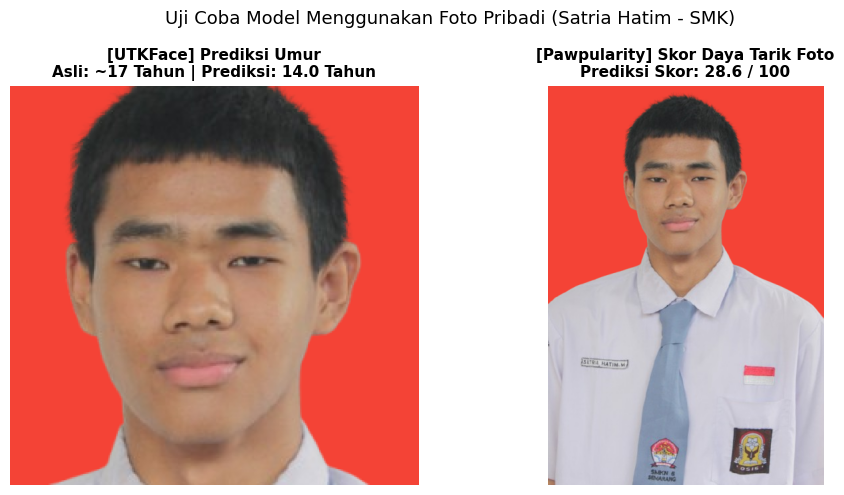

In [27]:
# ==============================================================================
# UJI COBA FOTO SENDIRI: PREDIKSI UMUR (UTKFace) & SKOR PAWPULARITY
# ==============================================================================
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# 1. Muat Foto Asli & Konversi ke RGB (Cegah error channel 4 RGBA)
img_path = 'foto.png'  # Upload foto.png ke root /content/ di Colab
raw_img = Image.open(img_path).convert('RGB')
w, h = raw_img.size

# 2. Crop Wajah untuk Model UTKFace (Sesuai format training UTKFace)
# Proporsi wajah pas (dari dahi sampai dagu)
face_crop = raw_img.crop((int(w * 0.19), int(h * 0.05), int(w * 0.81), int(h * 0.47)))

# 3. Preprocessing Model 1: Prediksi Umur (Input 160x160)
img_age = face_crop.resize((160, 160))
x_age = np.array(img_age, dtype=np.float32) / 255.0
pred_age = model.predict(np.expand_dims(x_age, 0), verbose=0).ravel()[0]

# 4. Preprocessing Model 2: Prediksi Pawpularity (Input 224x224)
img_paw = raw_img.resize((224, 224))
x_paw = np.array(img_paw, dtype=np.float32) / 255.0
# Jika model pawpularity disimpan terpisah (mis. model_paw), ganti model -> model_paw
pred_paw = model.predict(np.expand_dims(x_paw, 0), verbose=0).ravel()[0]

# 5. Visualisasi Hasil Laporan (2 Panel Berdampingan)
plt.figure(figsize=(10, 5))

# Subplot A: Prediksi Umur
plt.subplot(1, 2, 1)
plt.imshow(face_crop)
plt.title(f"[UTKFace] Prediksi Umur\nAsli: ~17 Tahun | Prediksi: {pred_age:.1f} Tahun", fontsize=11, fontweight='bold')
plt.axis('off')

# Subplot B: Prediksi Pawpularity
plt.subplot(1, 2, 2)
plt.imshow(raw_img)
plt.title(f"[Pawpularity] Skor Daya Tarik Foto\nPrediksi Skor: {pred_paw:.1f} / 100", fontsize=11, fontweight='bold')
plt.axis('off')

plt.suptitle("Uji Coba Model Menggunakan Foto Pribadi (Satria Hatim - SMK)", fontsize=13)
plt.tight_layout()
plt.savefig("hasil_ujicoba_pribadi.png", dpi=300, bbox_inches='tight')
plt.show()
